In [1]:
import os
os.environ['KAGGLE_KEY'] = 'd5e167e01b5efa43d64c38ad6167c7fe'
os.environ['KAGGLE_USERNAME'] = 'chomu6969'

In [2]:
import kagglehub

# Download latest version of the comprehensive soil classification dataset
path = kagglehub.dataset_download("ai4a-lab/comprehensive-soil-classification-datasets")
print("Path to dataset files:", path)

100%|██████████| 490M/490M [00:28<00:00, 18.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from pathlib import Path
from PIL import Image

dataset_path = Path(path)


print("Root directories under dataset path:")
for item in dataset_path.iterdir():
    if item.is_dir():
        print(f"  Folder: {item.name}")


def scan_dataset(directory):
    found_classes = {}
    for root, dirs, files in os.walk(directory):

        img_files = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if img_files:
            folder_name = os.path.basename(root)
            found_classes[root] = len(img_files)
    return found_classes

structure = scan_dataset(dataset_path)
for folder, count in list(structure.items())[:15]:
    print(f"{folder}: {count} images")

Root directories under dataset path:
  Folder: CyAUG-Dataset
  Folder: Orignal-Dataset
/root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1/CyAUG-Dataset/Yellow_Soil: 1401 images
/root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1/CyAUG-Dataset/Alluvial_Soil: 692 images
/root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1/CyAUG-Dataset/Mountain_Soil: 201 images
/root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1/CyAUG-Dataset/Black_Soil: 1173 images
/root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1/CyAUG-Dataset/Arid_Soil: 284 images
/root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1/CyAUG-Dataset/Red_Soil: 1126 images
/root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1/CyAUG-Dataset/Later

Detected Soil Classes: ['CyAUG-Dataset', 'Orignal-Dataset']
Images per class: {'CyAUG-Dataset': 5096, 'Orignal-Dataset': 1188}


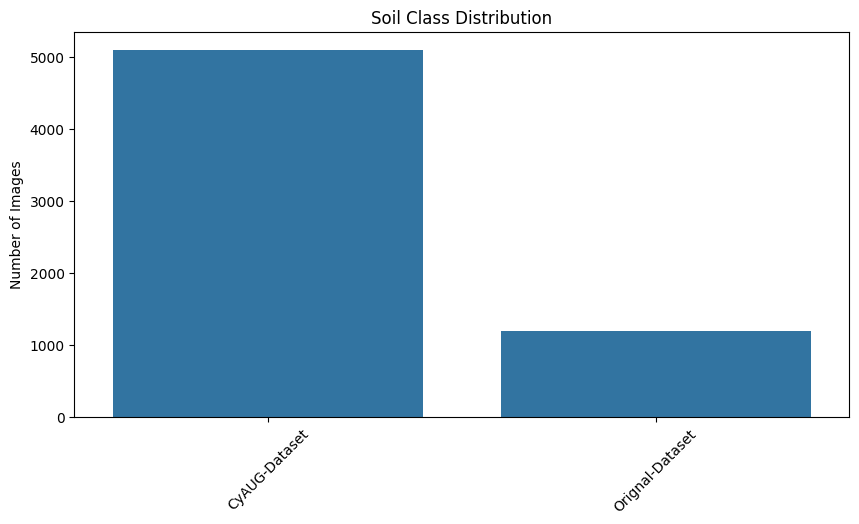

In [6]:

base_img_dir = dataset_path
subfolders = [d for d in base_img_dir.iterdir() if d.is_dir()]


if len(subfolders) == 1:
    base_img_dir = subfolders[0]
    subfolders = [d for d in base_img_dir.iterdir() if d.is_dir()]

classes = [d.name for d in subfolders]
print(f"Detected Soil Classes: {classes}")

class_counts = {d.name: len(list(d.glob('**/*.jpg')) + list(d.glob('**/*.jpeg')) + list(d.glob('**/*.png'))) for d in subfolders}
print("Images per class:", class_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
plt.title('Soil Class Distribution')
plt.xticks(rotation=45)
plt.ylabel('Number of Images')
plt.show()

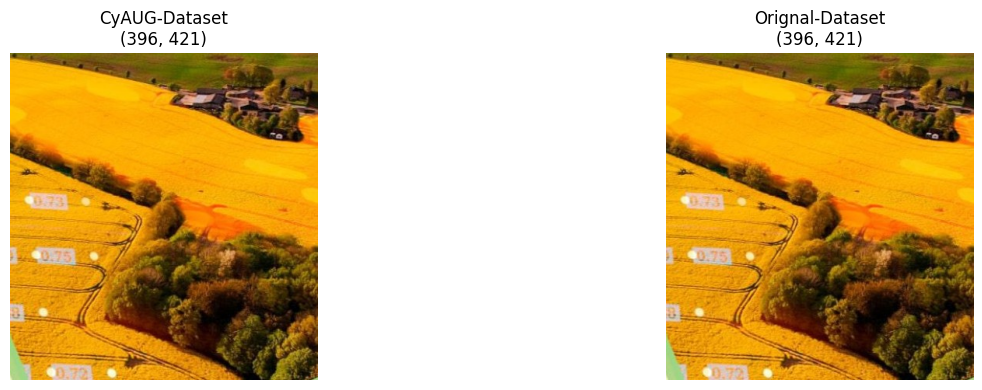

In [7]:

fig, axes = plt.subplots(1, len(subfolders), figsize=(16, 4))
for i, folder in enumerate(subfolders):
    img_files = list(folder.glob('**/*.jpg')) + list(folder.glob('**/*.jpeg')) + list(folder.glob('**/*.png'))
    if img_files:
        img = Image.open(img_files[0])
        axes[i].imshow(img)
        axes[i].set_title(f"{folder.name}\n{img.size}")
        axes[i].axis('off')
    else:
        axes[i].text(0.5, 0.5, 'No Image Found', ha='center', va='center')
        axes[i].axis('off')
plt.tight_layout()
plt.show()

### Deep Exploratory Data Analysis (EDA)
Let's perform a comprehensive analysis on the actual soil types (classes) contained within the `Orignal-Dataset` subdirectory.

=== Dataset Summary ===


,Soil_Type,Original_Count,CyAUG_Count
0,Alluvial_Soil,51,692
1,Arid_Soil,284,284
2,Black_Soil,255,1173
3,Laterite_Soil,219,219
4,Mountain_Soil,201,201
5,Red_Soil,109,1126
6,Yellow_Soil,69,1401


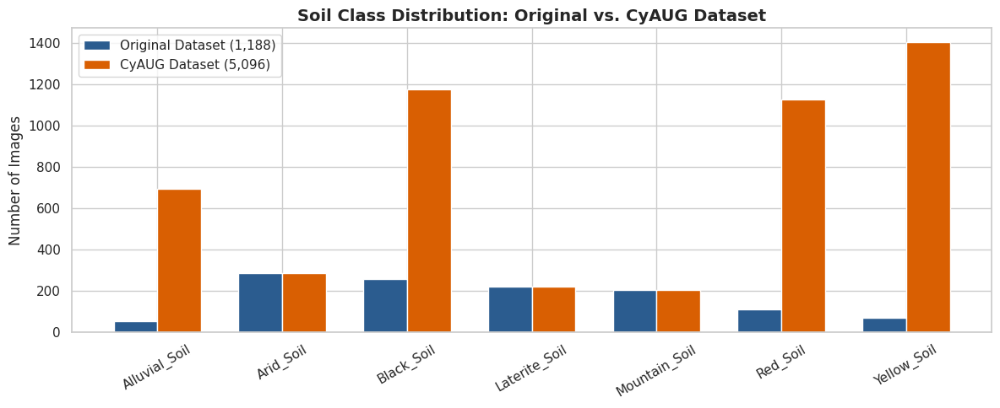

In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Set style
sns.set_theme(style="whitegrid")
dataset_path = Path(path)

orig_dir = dataset_path / "Orignal-Dataset"
cyaug_dir = dataset_path / "CyAUG-Dataset"

# 1. Compare Class Distributions (Original vs CyAUG)
def get_class_counts(directory):
    counts = {}
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            imgs = [f for f in class_dir.iterdir() if f.suffix.lower() in ('.jpg', '.jpeg', '.png')]
            counts[class_dir.name] = len(imgs)
    return counts

orig_counts = get_class_counts(orig_dir)
cyaug_counts = get_class_counts(cyaug_dir)

df_counts = pd.DataFrame({
    'Soil_Type': list(orig_counts.keys()),
    'Original_Count': list(orig_counts.values()),
    'CyAUG_Count': list(cyaug_counts.values())
})
print("=== Dataset Summary ===")
display(df_counts)

# Plot Side-by-Side Bar Chart
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(df_counts['Soil_Type']))
width = 0.35

ax.bar(x - width/2, df_counts['Original_Count'], width, label='Original Dataset (1,188)', color='#2b5c8f')
ax.bar(x + width/2, df_counts['CyAUG_Count'], width, label='CyAUG Dataset (5,096)', color='#d95f02')

ax.set_ylabel('Number of Images')
ax.set_title('Soil Class Distribution: Original vs. CyAUG Dataset', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_counts['Soil_Type'], rotation=30)
ax.legend()
plt.tight_layout()
plt.show()

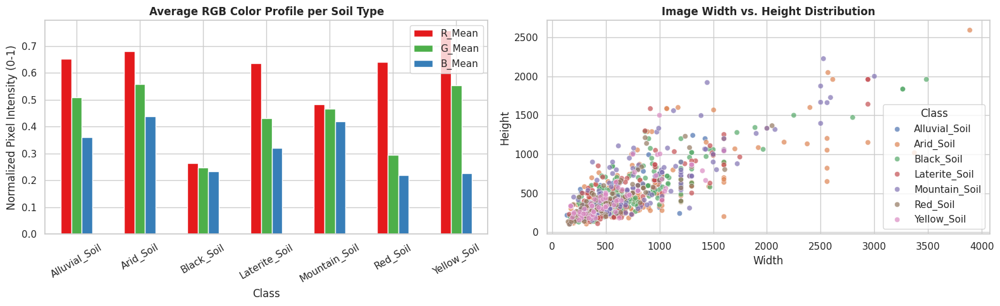

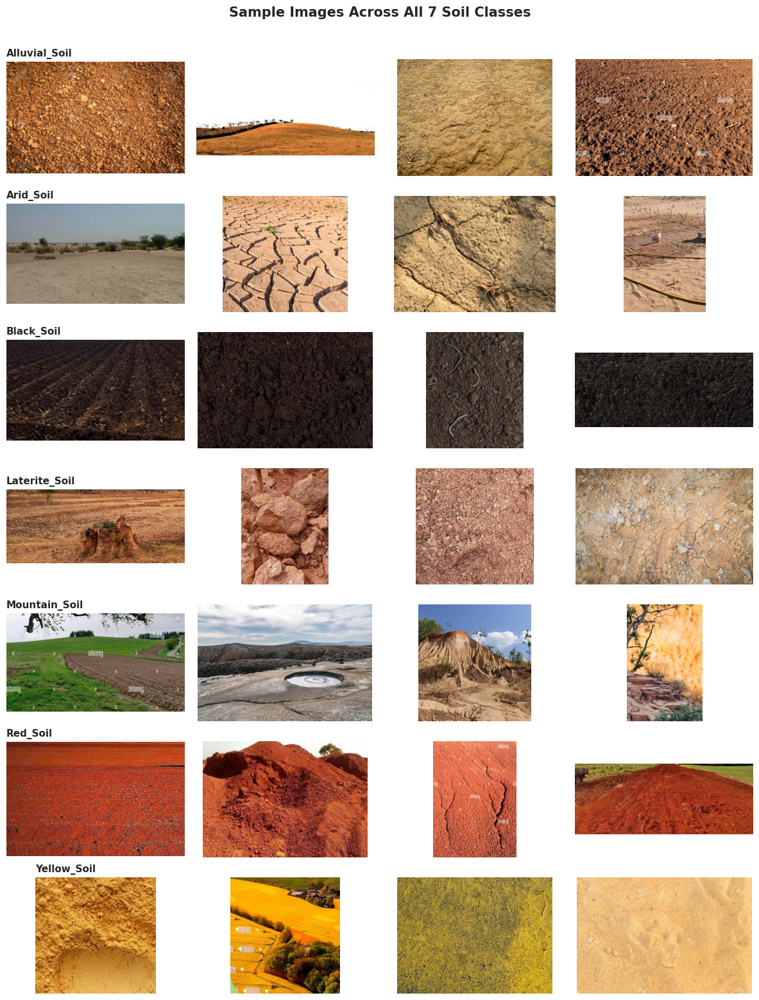

In [ ]:
# 2. Analyze Image Dimensions & RGB Means (on Original Dataset)
meta_data = []
for class_dir in sorted(orig_dir.iterdir()):
    if class_dir.is_dir():
        for img_path in class_dir.iterdir():
            if img_path.suffix.lower() in ('.jpg', '.jpeg', '.png'):
                try:
                    with Image.open(img_path) as img:
                        img_rgb = img.convert('RGB')
                        w, h = img_rgb.size
                        arr = np.array(img_rgb) / 255.0
                        r_mean, g_mean, b_mean = arr.mean(axis=(0, 1))
                        meta_data.append({
                            'Class': class_dir.name,
                            'Width': w,
                            'Height': h,
                            'Aspect_Ratio': round(w / h, 2),
                            'R_Mean': r_mean,
                            'G_Mean': g_mean,
                            'B_Mean': b_mean,
                            'Path': str(img_path)
                        })
                except Exception as e:
                    print(f"Corrupt image skipped: {img_path}")

df_meta = pd.DataFrame(meta_data)

# Plot RGB Channel Distributions per Soil Type
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Mean RGB values per class
rgb_means = df_meta.groupby('Class')[['R_Mean', 'G_Mean', 'B_Mean']].mean()
rgb_means.plot(kind='bar', ax=axes[0], color=['#e41a1c', '#4daf4a', '#377eb8'])
axes[0].set_title('Average RGB Color Profile per Soil Type', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Normalized Pixel Intensity (0-1)')
axes[0].tick_params(axis='x', rotation=30)

# Plot 2: Image Dimension Scatter Plot
sns.scatterplot(data=df_meta, x='Width', y='Height', hue='Class', alpha=0.7, ax=axes[1])
axes[1].set_title('Image Width vs. Height Distribution', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Sample Grid Visualization (1 row per soil class, 4 samples each)
classes = sorted(df_meta['Class'].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(12, 2.2 * len(classes)))

for i, cls in enumerate(classes):
    sample_paths = df_meta[df_meta['Class'] == cls]['Path'].sample(4, random_state=42).values
    for j, p in enumerate(sample_paths):
        img = Image.open(p).convert('RGB')
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(f"{cls}", fontsize=11, fontweight='bold', loc='left')

plt.suptitle('Sample Images Across All 7 Soil Classes', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Actual Soil Classes: ['Yellow_Soil', 'Alluvial_Soil', 'Mountain_Soil', 'Black_Soil', 'Arid_Soil', 'Red_Soil', 'Laterite_Soil']


/tmp/ipykernel_1520/1951456392.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(soil_class_counts.keys()), y=list(soil_class_counts.values()), palette='viridis')


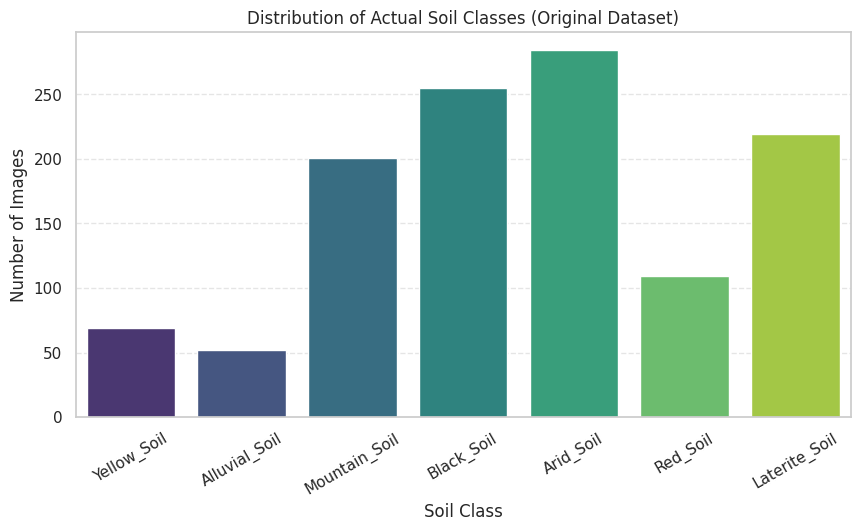

In [ ]:
import cv2

soil_types_dir = dataset_path / 'Orignal-Dataset'
soil_classes = [d.name for d in soil_types_dir.iterdir() if d.is_dir()]

print(f"Actual Soil Classes: {soil_classes}")

# 1. Class Distribution Analysis
soil_class_counts = {sc: len(list((soil_types_dir / sc).glob('**/*'))) for sc in soil_classes}

plt.figure(figsize=(10, 5))
sns.barplot(x=list(soil_class_counts.keys()), y=list(soil_class_counts.values()), palette='viridis')
plt.title('Distribution of Actual Soil Classes (Original Dataset)')
plt.xlabel('Soil Class')
plt.ylabel('Number of Images')
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Average dimensions and aspect ratios per soil type:


,Class,Width,Height,Aspect_Ratio
0,Alluvial_Soil,693.45,480.15,1.580001
1,Arid_Soil,840.75,646.10,1.347099
2,Black_Soil,767.75,516.50,1.660863
3,Laterite_Soil,866.50,629.80,1.463293
4,Mountain_Soil,1013.95,694.30,1.497254
5,Red_Soil,505.90,431.55,1.209983
6,Yellow_Soil,676.45,588.85,1.190995


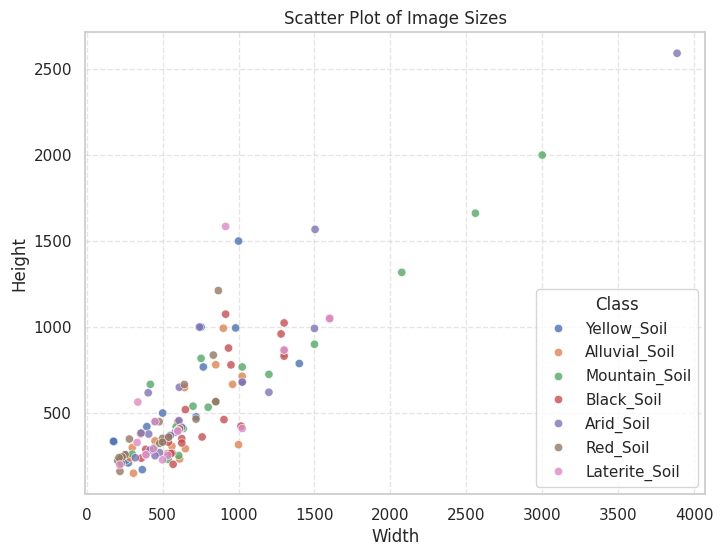

In [ ]:
# 2. Analyze Image Shapes & Dimensions
shapes = []
for sc in soil_classes:
    img_files = list((soil_types_dir / sc).glob('*'))
    for img_path in img_files[:20]: # Sample 20 images per class for efficiency
        try:
            with Image.open(img_path) as img:
                shapes.append((img.width, img.height, sc))
        except Exception:
            continue

df_shapes = pd.DataFrame(shapes, columns=['Width', 'Height', 'Class'])
df_shapes['Aspect_Ratio'] = df_shapes['Width'] / df_shapes['Height']

print("Average dimensions and aspect ratios per soil type:")
display(df_shapes.groupby('Class').mean().reset_index())

# Visualize height vs width distribution
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_shapes, x='Width', y='Height', hue='Class', alpha=0.8)
plt.title('Scatter Plot of Image Sizes')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

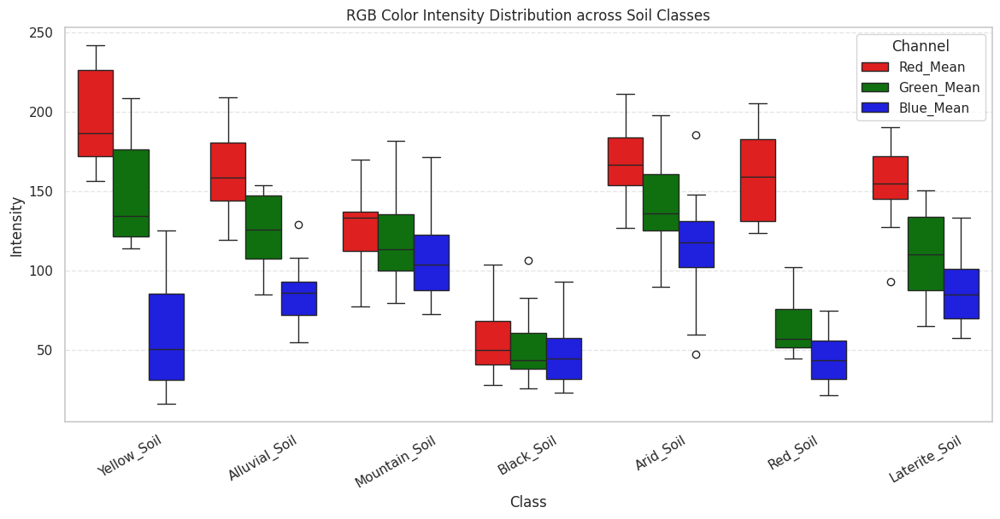

In [ ]:
# 3. Color Channel Distribution (Average RGB Values per Class)
color_data = []
for sc in soil_classes:
    img_files = list((soil_types_dir / sc).glob('*'))
    for img_path in img_files[:15]: # Sample 15 images per class
        img_np = cv2.imread(str(img_path))
        if img_np is not None:
            # cv2 reads in BGR, let's calculate mean of Blue, Green, Red
            mean_b = np.mean(img_np[:, :, 0])
            mean_g = np.mean(img_np[:, :, 1])
            mean_r = np.mean(img_np[:, :, 2])
            color_data.append([sc, mean_r, mean_g, mean_b])

df_color = pd.DataFrame(color_data, columns=['Class', 'Red_Mean', 'Green_Mean', 'Blue_Mean'])
df_color_melted = df_color.melt(id_vars='Class', var_name='Channel', value_name='Intensity')

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_color_melted, x='Class', y='Intensity', hue='Channel', palette=['red', 'green', 'blue'])
plt.title('RGB Color Intensity Distribution across Soil Classes')
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

With our comprehensive EDA completed, we can proceed to correctly align our training generators to target `Orignal-Dataset` (or `CyAUG-Dataset` if we want the augmented subset).

In [ ]:
import os
from pathlib import Path
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Set correct target folder explicitly for the 7 soil classes
soil_types_dir = Path(path) / 'Orignal-Dataset'

img_height = 224  # MobileNetV2 standard input height
img_width = 224   # MobileNetV2 standard input width
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

print("Loading training images:")
train_generator = datagen.flow_from_directory(
    soil_types_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

print("\nLoading validation images:")
val_generator = datagen.flow_from_directory(
    soil_types_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Loading training images:
Found 954 images belonging to 7 classes.

Loading validation images:
Found 234 images belonging to 7 classes.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, optimizers

# 1. Load pre-trained MobileNetV2
base_model = MobileNetV2(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights='imagenet'
)

# Initially freeze the entire base model
base_model.trainable = False

# 2. Build final Sequential pipeline
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(train_generator.num_classes, activation='softmax')
])

# Compile with standard learning rate for initial feature extraction
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,621,255 (10.00 MB)

 Trainable params: 362,503 (1.38 MB)

 Non-trainable params: 2,258,752 (8.62 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import optimizers

# Callbacks to stabilize training and enhance convergence
callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6, verbose=1)
]

print("Phase 1: Training Classification Head...")
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    callbacks=callbacks
)

# Phase 2: Unfreeze top layers of the base model for fine-tuning
print("\nPhase 2: Fine-Tuning Top Layers...")
base_model.trainable = True

# Freeze all layers except the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a very low learning rate for gentle fine-tuning
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_epochs = 10
fine_tune_history = model.fit(
    train_generator,
    epochs=fine_tune_epochs,
    validation_data=val_generator,
    callbacks=callbacks
)

Phase 1: Training Classification Head...
Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 103s 3s/step - accuracy: 0.4822 - loss: 1.5829 - val_accuracy: 0.5470 - val_loss: 1.3236 - learning_rate: 0.0010
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 83s 3s/step - accuracy: 0.6887 - loss: 0.9237 - val_accuracy: 0.7650 - val_loss: 0.8000 - learning_rate: 0.0010
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 80s 3s/step - accuracy: 0.7222 - loss: 0.7793 - val_accuracy: 0.7350 - val_loss: 0.7524 - learning_rate: 0.0010
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.7904 - loss: 0.6717 - val_accuracy: 0.7607 - val_loss: 0.7613 - learning_rate: 0.0010
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 80s 3s/step - accuracy: 0.7736 - loss: 0.6569 - val_accuracy: 0.7949 - val_loss: 0.6730 - learning_rate: 0.0010
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 78s 3s/step - accuracy: 0.7977 - loss: 0.5969 - val_accuracy: 0.7735 - val_loss: 0.7077 - learning_rate: 0.0010
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 79s 3s/step - accura

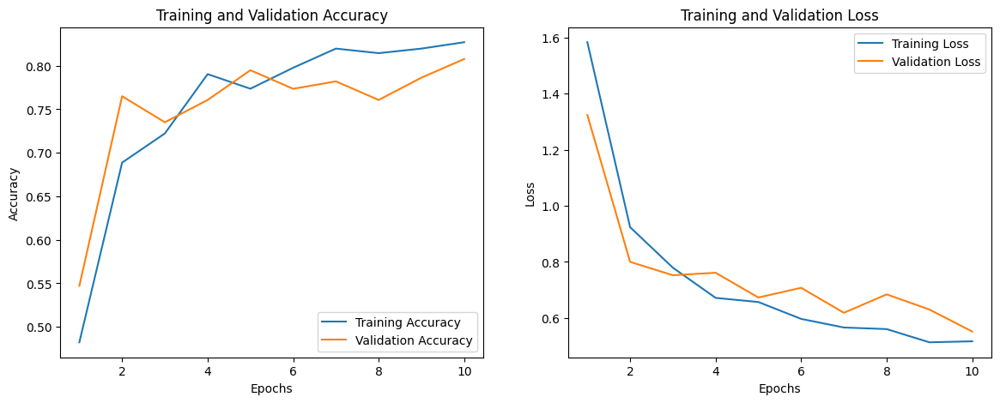

In [ ]:
# Plot validation accuracy and loss over epochs
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

# Dynamically get the number of epochs to avoid NameError
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
# Evaluate the fine-tuned high-accuracy model on the validation set
eval_results = model.evaluate(val_generator)
print(f"Final Validation Loss: {eval_results[0]:.4f}")
print(f"Final Validation Accuracy: {eval_results[1]*100:.2f}%")


model_save_path = 'soil_classification_model_optimized.keras'
model.save(model_save_path)
print(f"High-accuracy model saved successfully to {model_save_path}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.8205 - loss: 0.5945
Final Validation Loss: 0.5945
Final Validation Accuracy: 82.05%
High-accuracy model saved successfully to soil_classification_model_optimized.keras


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


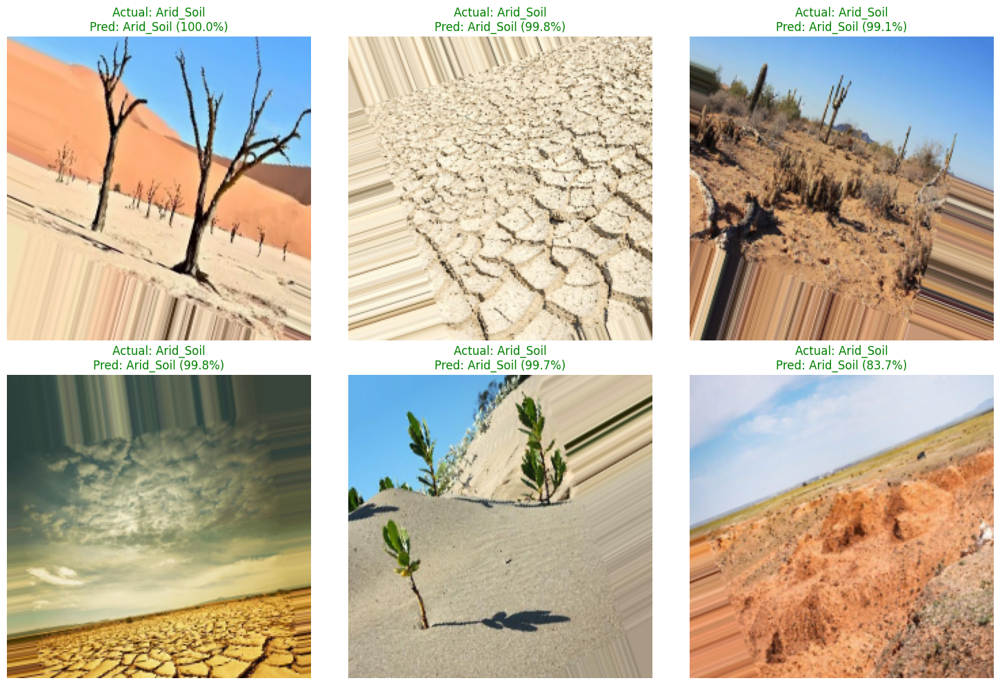

In [ ]:
# Fetch a batch of validation images and visualize predictions from the optimized model
x_batch, y_batch = next(val_generator)
predictions = model.predict(x_batch)

# Get class labels map dynamically representing the 7 classes
class_labels = {v: k for k, v in val_generator.class_indices.items()}

plt.figure(figsize=(15, 10))
for i in range(min(6, len(x_batch))):
    plt.subplot(2, 3, i + 1)
    plt.imshow(x_batch[i])

    actual_label = class_labels[np.argmax(y_batch[i])]
    pred_label = class_labels[np.argmax(predictions[i])]
    confidence = np.max(predictions[i]) * 100

    title_color = 'green' if actual_label == pred_label else 'red'
    plt.title(f"Actual: {actual_label}\nPred: {pred_label} ({confidence:.1f}%)", color=title_color)
    plt.axis('off')

plt.tight_layout()
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step


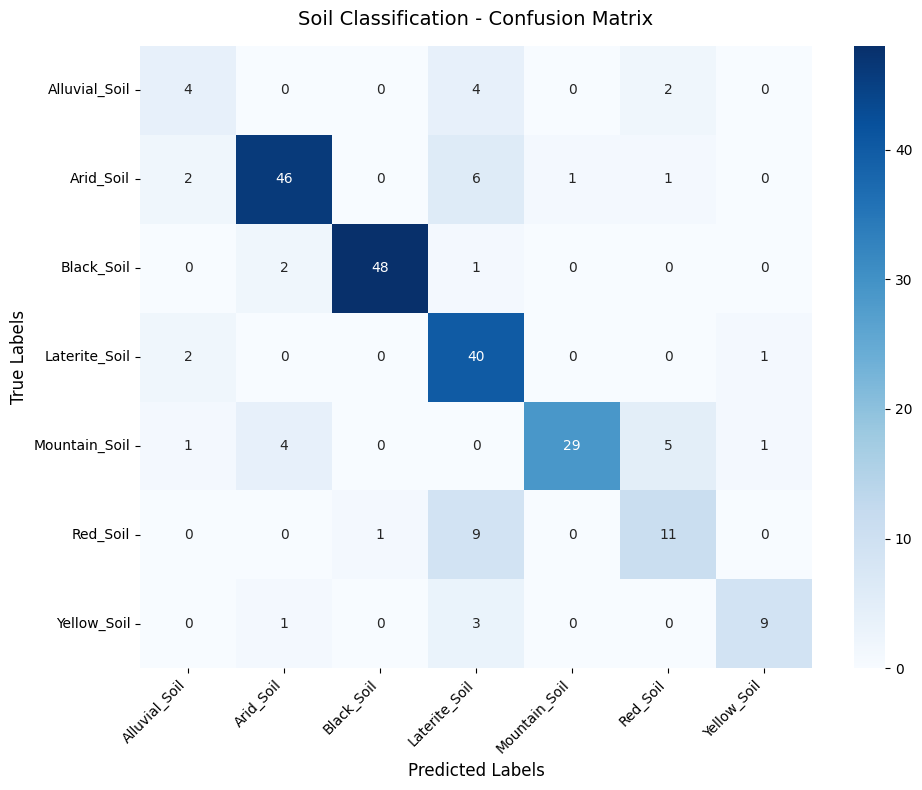

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Reset the validation generator to ensure ordered predictions
val_generator.reset()

# Get predictions and ground truth labels
predictions = model.predict(val_generator, verbose=1)
y_pred = np.argmax(predictions, axis=1)
y_true = val_generator.classes

# Extract target class names dynamically
class_names = list(val_generator.class_indices.keys())

# Compute Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Soil Classification - Confusion Matrix', fontsize=14, pad=15)
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Print classification report for detailed precision, recall, and f1-score metrics
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

Classification Report:

               precision    recall  f1-score   support

Alluvial_Soil       0.44      0.40      0.42        10
    Arid_Soil       0.87      0.82      0.84        56
   Black_Soil       0.98      0.94      0.96        51
Laterite_Soil       0.63      0.93      0.75        43
Mountain_Soil       0.97      0.72      0.83        40
     Red_Soil       0.58      0.52      0.55        21
  Yellow_Soil       0.82      0.69      0.75        13

     accuracy                           0.80       234
    macro avg       0.76      0.72      0.73       234
 weighted avg       0.82      0.80      0.80       234



### High-Accuracy Soil Classification Pipeline
To achieve significantly greater accuracy, we will:
1. Use the **`CyAUG-Dataset`** which is balanced and heavily augmented (5,096 images instead of 1,188 imbalanced images in the Original Dataset).
2. Use a modern, highly-accurate architecture: **EfficientNetV2B0**.
3. Train with **Label Smoothing** loss to improve generalization.
4. Apply **Cosine Decay** learning rate scheduling and early stopping.

In [8]:
import tensorflow as tf
import pandas as pd
import numpy as np
from pathlib import Path
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

# Define path and directory variables
dataset_path = Path('/root/.cache/kagglehub/datasets/ai4a-lab/comprehensive-soil-classification-datasets/versions/1')
cyaug_dir = dataset_path / 'CyAUG-Dataset'

# 1. Build DataFrame of Filepaths and Labels from CyAUG-Dataset
target_dir = cyaug_dir  # Change to orig_dir if you prefer training only on raw images
filepaths, labels = [], []

for class_dir in sorted(target_dir.iterdir()):
    if class_dir.is_dir():
        for img_path in class_dir.iterdir():
            if img_path.suffix.lower() in ('.jpg', '.jpeg', '.png'):
                filepaths.append(str(img_path))
                labels.append(class_dir.name)

df_data = pd.DataFrame({'filepath': filepaths, 'label': labels})

# Stratified Train / Val / Test Split (70% Train, 15% Val, 15% Test)
train_df, temp_df = train_test_split(
    df_data, test_size=0.30, stratify=df_data['label'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42
)

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")

# 2. Data Generators with MobileNetV2 Preprocessing
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)

val_test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

train_gen = train_datagen.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True
)

val_gen = val_test_datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

test_gen = val_test_datagen.flow_from_dataframe(
    test_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

# 3. Compute Class Weights to Fix Imbalance
classes_idx = np.unique(train_gen.classes)
weights = compute_class_weight(
    class_weight='balanced', classes=classes_idx, y=train_gen.classes
)
class_weights = dict(zip(classes_idx, weights))
print("Computed Class Weights:", class_weights)

Train samples: 3567 | Val samples: 764 | Test samples: 765
Found 3567 validated image filenames belonging to 7 classes.
Found 764 validated image filenames belonging to 7 classes.
Found 765 validated image filenames belonging to 7 classes.
Computed Class Weights: {np.int64(0): np.float64(1.0528335301062575), np.int64(1): np.float64(2.5606604450825556), np.int64(2): np.float64(0.6206716547764051), np.int64(3): np.float64(3.330532212885154), np.int64(4): np.float64(3.613981762917933), np.int64(5): np.float64(0.6466642494561277), np.int64(6): np.float64(0.5194408038444736)}


# **Build, Train, and Fine-Tune the Model**

In [9]:
# 4. Build MobileNetV2 Transfer Learning Model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet'
)
base_model.trainable = False  # Freeze base layers initially

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(7, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Stage 1: Train Top Classifier Head
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)

print("\n--- Stage 1: Training Top Layers ---")
history_stage1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=12,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

# Stage 2: Unfreeze Top 40 Layers of MobileNetV2 for Fine-Tuning
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),  # Lower LR for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\n--- Stage 2: Fine-Tuning Model ---")
history_stage2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

--- Stage 1: Training Top Layers ---
Epoch 1/12
112/112 ━━━━━━━━━━━━━━━━━━━━ 79s 577ms/step - accuracy: 0.7303 - loss: 0.9622 - val_accuracy: 0.8364 - val_loss: 0.4762 - learning_rate: 0.0010
Epoch 2/12
112/112 ━━━━━━━━━━━━━━━━━━━━ 50s 444ms/step - accuracy: 0.8565 - loss: 0.5375 - val_accuracy: 0.8560 - val_loss: 0.4630 - learning_rate: 0.0010
Epoch 3/12
112/112 ━━━━━━━━━━━━━━━━━━━━ 51s 456ms/step - accuracy: 0.8797 - loss: 0.4271 - val_accuracy: 0.8613 - val_loss: 0.4594 - learning_rate: 0.0010
Epoch 4/12
112/112 ━━━━━━━━━━━━━━━━━━━━ 50s 445ms/step - accuracy: 0.8811 - loss: 0.4477 - val_accuracy: 0.8613 - val_loss: 0.4390 - learning_rate: 0.0010
Epoch 5/12
112/112 ━━━━━━━━━━━━━━━━━━━━ 48s 433ms/step - accuracy: 0.8845 - loss: 0.4005 - val_accuracy: 0.8429 - val_loss: 0.5102 - learning_rate: 0.0010
Epoch 6/12
112/112 ━━━━━━━━━━━━━━━━━━━━ 50s 442ms/step - accuracy: 0.8929 - loss: 0.3686 - val_accuracy: 0.8717 - val_loss: 0.4349 - learn

In [15]:
# Stage 2: Safe & Stable Fine-Tuning
base_model.trainable = True

# Freeze all layers except the top 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# CRITICAL: Keep BatchNormalization layers in inference mode to prevent statistic corruption
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # Much safer lower learning rate
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Starting Stable Fine-Tuning (Top 30 Layers)...")
history_stage2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,  # Fewer epochs are usually enough for fine-tuning
    class_weight=class_weights,
    callbacks=[
        callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-7, verbose=1)
    ]
)

# Save the newly optimized model
model.save("best_soil_classifier_finetuned.keras")
print("Saved fine-tuned model successfully!")

Starting Stable Fine-Tuning (Top 30 Layers)...
Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 83s 588ms/step - accuracy: 0.8884 - loss: 0.3858 - val_accuracy: 0.6139 - val_loss: 1.7042 - learning_rate: 1.0000e-05
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 52s 462ms/step - accuracy: 0.9027 - loss: 0.3388 - val_accuracy: 0.6675 - val_loss: 1.4482 - learning_rate: 1.0000e-05
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 53s 470ms/step - accuracy: 0.9092 - loss: 0.3122 - val_accuracy: 0.7081 - val_loss: 1.1462 - learning_rate: 1.0000e-05
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 50s 446ms/step - accuracy: 0.9038 - loss: 0.3287 - val_accuracy: 0.7382 - val_loss: 0.9958 - learning_rate: 1.0000e-05
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 52s 461ms/step - accuracy: 0.9022 - loss: 0.3083 - val_accuracy: 0.7683 - val_loss: 0.8564 - learning_rate: 1.0000e-05
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 51s 454ms/step - accuracy: 0.9041 - loss: 0.3176 - val_accuracy: 0.7814 - val_loss: 0.7387 - learning_rate: 1.0000e-05

24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 225ms/step - accuracy: 0.9046 - loss: 0.2919

Final Test Accuracy: 90.46%
24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 290ms/step

=== Classification Report ===
               precision    recall  f1-score   support

Alluvial_Soil       0.68      0.94      0.79       104
    Arid_Soil       0.93      0.86      0.89        43
   Black_Soil       0.98      0.97      0.97       176
Laterite_Soil       0.71      0.67      0.69        33
Mountain_Soil       0.93      0.83      0.88        30
     Red_Soil       0.95      0.93      0.94       169
  Yellow_Soil       0.99      0.86      0.92       210

     accuracy                           0.90       765
    macro avg       0.88      0.87      0.87       765
 weighted avg       0.92      0.90      0.91       765



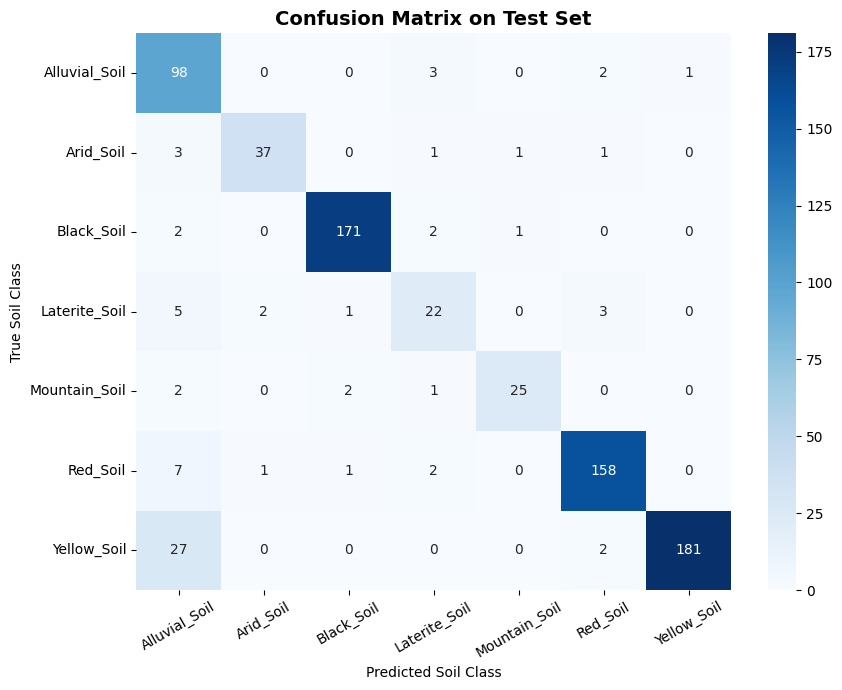

In [16]:
# Evaluate on Test Set
test_loss, test_acc = model.evaluate(test_gen)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%")

# Predictions & Confusion Matrix
y_pred_probs = model.predict(test_gen)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())

print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix on Test Set', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Soil Class')
plt.ylabel('True Soil Class')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

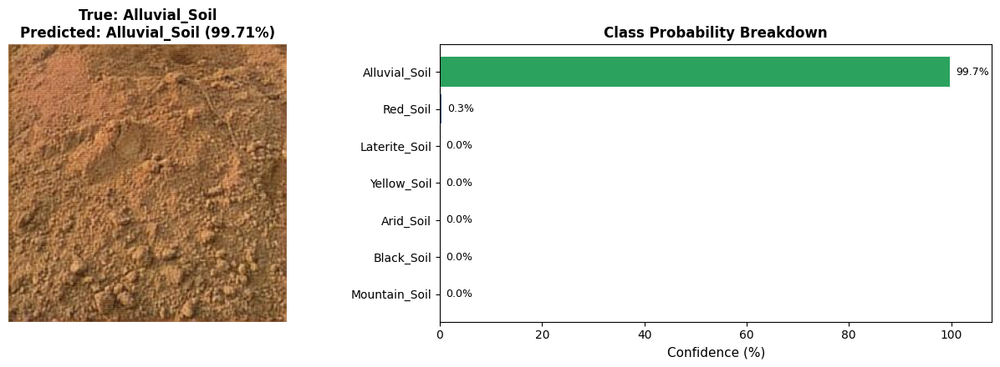

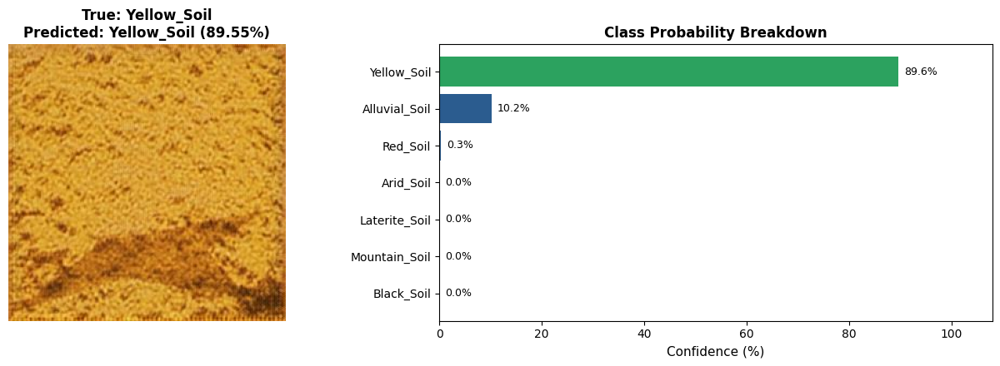

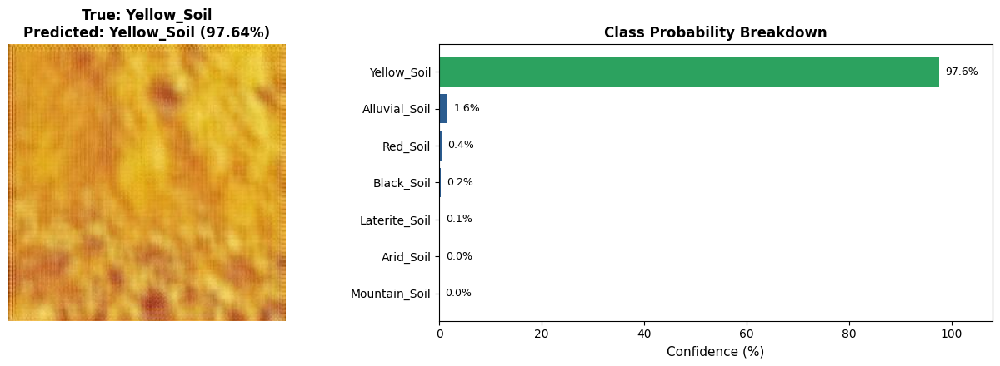

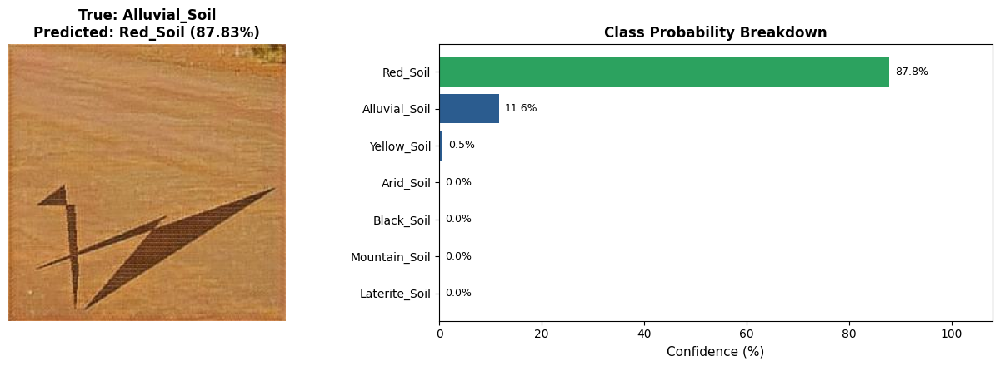

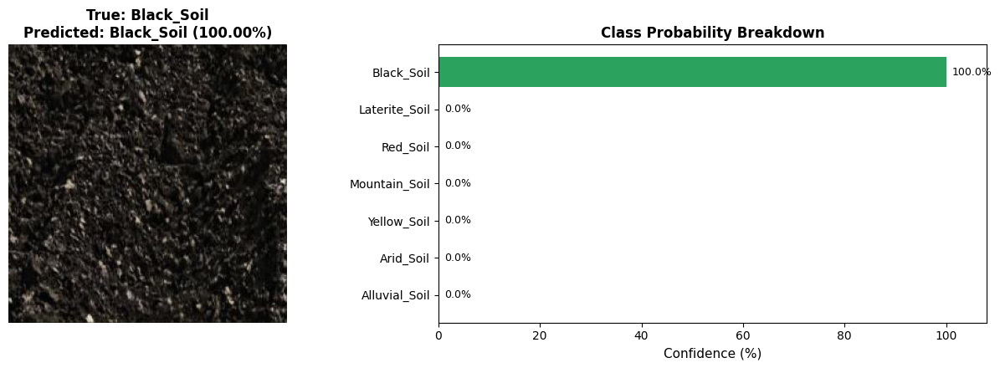

In [22]:
# Test on 5 Random Unseen Images from the Test Split
for _, sample_row in test_df.sample(5, random_state=42).iterrows():
    predict_single_soil_image(
        image_path=sample_row['filepath'],
        model_instance=model,
        class_map=idx_to_class,
        true_label=sample_row['label']
    )

In [24]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define the updated targeted data augmentation strategy
# We add color, contrast, and scaling properties to make the model robust to hue overlaps and texture scales
targeted_train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=40,          # Enhanced rotation to achieve full orientation invariance
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.3,             # Deeper zoom to emphasize micro-texture features
    horizontal_flip=True,
    vertical_flip=True,         # Soils have no true 'up' or 'down' relative to camera angles
    brightness_range=[0.7, 1.3], # Color and lighting jitter to handle shade variation
    fill_mode='nearest'
)

# We keep validation/test generators standard (rescaled/preprocessed only)
val_test_datagen_standard = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

# Regenerate data flow pipes using the newly augmented configurations
train_gen = targeted_train_datagen.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True
)

val_gen = val_test_datagen_standard.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

test_gen = val_test_datagen_standard.flow_from_dataframe(
    test_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

print("Targeted augmentation pipeline loaded successfully! You are now ready to retrain or fine-tune.")

Found 3567 validated image filenames belonging to 7 classes.
Found 764 validated image filenames belonging to 7 classes.
Found 765 validated image filenames belonging to 7 classes.
Targeted augmentation pipeline loaded successfully! You are now ready to retrain or fine-tune.


In [21]:
import pandas as pd

# Create a structured DataFrame representing the confusion matrix
cm_df = pd.DataFrame(cm, index=[f"True {name}" for name in class_names], columns=[f"Pred {name}" for name in class_names])

# Display the styled DataFrame
display(cm_df.style.background_gradient(cmap='Blues').set_caption("Confusion Matrix Summary Table (Test Set)"))

,Pred Alluvial_Soil,Pred Arid_Soil,Pred Black_Soil,Pred Laterite_Soil,Pred Mountain_Soil,Pred Red_Soil,Pred Yellow_Soil
True Alluvial_Soil,98,0,0,3,0,2,1
True Arid_Soil,3,37,0,1,1,1,0
True Black_Soil,2,0,171,2,1,0,0
True Laterite_Soil,5,2,1,22,0,3,0
True Mountain_Soil,2,0,2,1,25,0,0
True Red_Soil,7,1,1,2,0,158,0
True Yellow_Soil,27,0,0,0,0,2,181


Found 17 misclassified samples for Alluvial and Laterite soils.


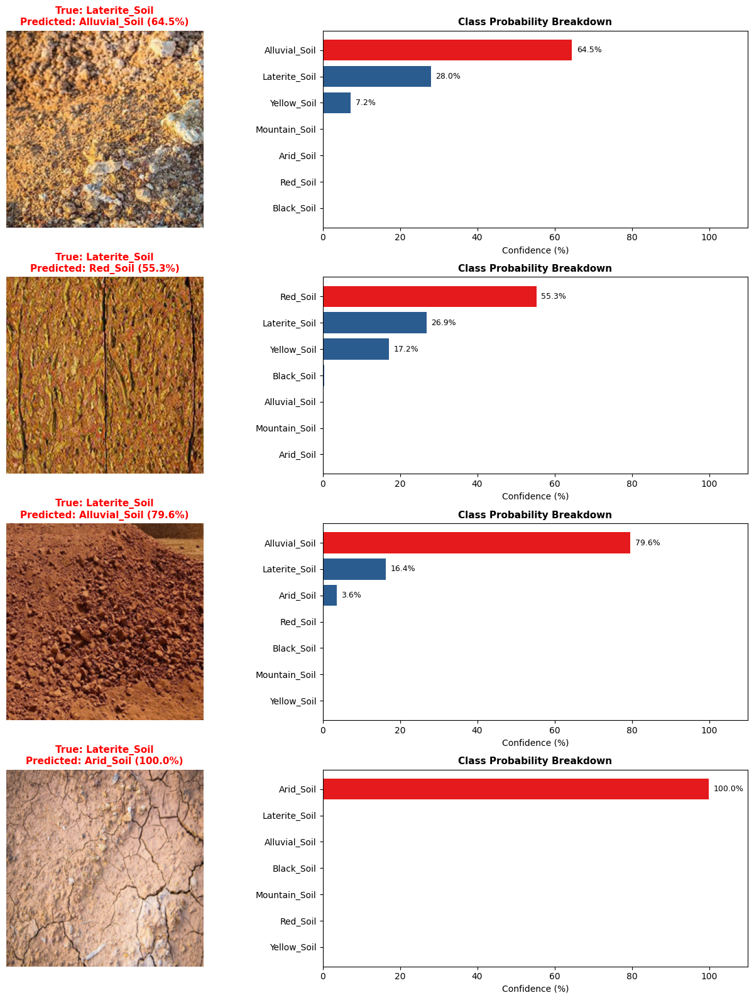

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

# Ensure we have predictions generated
y_pred_probs = model.predict(test_gen, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())

# Identify Indices where True Class is Alluvial_Soil or Laterite_Soil but Predicted Class is incorrect
target_classes = ['Alluvial_Soil', 'Laterite_Soil']
target_indices = [test_gen.class_indices[cls] for cls in target_classes]

error_indices = []
for idx in range(len(y_true)):
    if y_true[idx] in target_indices and y_true[idx] != y_pred[idx]:
        error_indices.append(idx)

if len(error_indices) == 0:
    print("No prediction errors found for Alluvial_Soil or Laterite_Soil on the test set!")
else:
    print(f"Found {len(error_indices)} misclassified samples for Alluvial and Laterite soils.")
    # Display up to 4 errors
    num_to_display = min(4, len(error_indices))
    fig, axes = plt.subplots(num_to_display, 2, figsize=(14, 4 * num_to_display))
    if num_to_display == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, idx in enumerate(error_indices[:num_to_display]):
        # Load the image
        img_path = test_df.iloc[idx]['filepath']
        true_lbl = test_df.iloc[idx]['label']
        pred_lbl = class_names[y_pred[idx]]
        confidence = y_pred_probs[idx][y_pred[idx]] * 100

        with Image.open(img_path) as img:
            img_rgb = img.convert('RGB').resize((224, 224))

        # Plot Image
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].axis('off')
        axes[i, 0].set_title(f"True: {true_lbl}\nPredicted: {pred_lbl} ({confidence:.1f}%)", fontsize=11, color='red', fontweight='bold')

        # Plot Bar Chart Breakdown
        sorted_probs_idx = np.argsort(y_pred_probs[idx])
        sorted_classes = [class_names[k] for k in sorted_probs_idx]
        sorted_probs = [y_pred_probs[idx][k] * 100 for k in sorted_probs_idx]
        colors = ['#2b5c8f' if k != y_pred[idx] else '#e41a1c' for k in sorted_probs_idx]

        bars = axes[i, 1].barh(sorted_classes, sorted_probs, color=colors)
        axes[i, 1].set_xlim(0, 110)
        axes[i, 1].set_xlabel('Confidence (%)')
        axes[i, 1].set_title('Class Probability Breakdown', fontsize=11, fontweight='bold')

        for bar in bars:
            width = bar.get_width()
            if width > 0.5:
                axes[i, 1].text(width + 1.2, bar.get_y() + bar.get_height()/2, f"{width:.1f}%", va='center', fontsize=9)

    plt.tight_layout()
    plt.show()